# Requirements to collpase requirements tables Note + Making Concordances Concord - Tony Gui

In [34]:
import pandas as pd
from IPython.display import clear_output
import numpy as np
from statsmodels.tsa.api import VAR
import os
from data_cleaning_functions import requirements_clean, concordance_PCE_clean, \
    find_intermediate_industries, concordance_PCQ_clean, get_sales_from_make_matrix, clean_make_matrix, \
    get_demand_shock_from_shaipro_output, get_expenditure_weights_from_shapiro_outputs,plot_shapiro_graph_from_shapiro_ouput,clean_bea_PQE_table, get_final_demand_from_use_table

from pathlib import Path
import matplotlib.pyplot as plt

script_dir = str(Path().resolve().parent)
file_path = os.path.join(script_dir) + "/" 
shapiro_file =  file_path + "Shapiro"
raw_data_path = file_path + "raw_bea_data" 

# Tony's Frankensteined Concordance 🥹

## What I am going to do is extend the BEA PCE to Industry concordance to include the intermediate industries by simply assigning each to an "unassigned" PCE product 

### unassigned is in quotes because technically the PCE to Industry concordance accounts total expenditure but PPI data from BLS isn't even quantity and expenditure so i hope this will do for now 

In [35]:
use_table = pd.read_excel(os.path.join(raw_data_path, "Use_SUT_Framework_2017_DET.xlsx"), sheet_name="2017")
intermediate_industries = find_intermediate_industries(use_table)
intermediate_industries = intermediate_industries.iloc[:, [0]]
intermediate_industries = intermediate_industries.sort_values(by="Industry")
# intermediate_industries

In [36]:
concordance = pd.read_excel(os.path.join(raw_data_path, "PCEBridge_2017_DET.xlsx"), sheet_name="2017")
concordance = concordance_PCE_clean(concordance)
# concordance

In [37]:
bea_quantities = pd.read_excel(os.path.join(raw_data_path, 'BEA Monthly Quantities.xlsx')) # read raw BEA quantities
bea_quantities = clean_bea_PQE_table(bea_quantities, "Quantities", long=True) 
bea_products = bea_quantities[["products"]].drop_duplicates()
# bea_products

In [38]:
# 1) sets
missing_inds = (
    intermediate_industries["Industry"]
    .astype(str).str.strip()
    .dropna().drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

used_products = set(
    concordance["PCE Bridge Products"]
    .astype(str).str.strip()
    .dropna().unique()
)

all_products = (
    (bea_products["products"] if isinstance(bea_products, pd.DataFrame) else bea_products)
    .astype(str).str.strip()
    .dropna().drop_duplicates()
)

unused_products = (
    all_products[~all_products.isin(used_products)]
    .sort_values()
    .reset_index(drop=True)
)

# 2) sanity check: need at least 143 unused products for a unique assignment
if len(unused_products) < len(missing_inds):
    raise ValueError(
        f"Not enough unused products: {len(unused_products)} unused vs {len(missing_inds)} industries."
    )

# 3) build the new concordance-style table (143 x 2)
bad_products = [
    "additional aggregates:",
    "durable goods:",
    "market-based personal consumption expenditures (pce):",
    "net expenditures abroad by u.s. residents",
    "net foreign travel",
    "nondurable goods:",
    "of which:"
]

unused_products_clean = unused_products[~unused_products.isin(bad_products)].reset_index(drop=True)

new_concordance_fill = pd.DataFrame({
    "PCE Bridge Products": unused_products_clean.iloc[:len(missing_inds)].to_list(),
    "PCE Bridge Industries": missing_inds.to_list(),
})

# new_concordance_fill

In [39]:
concordance_stacked = pd.concat([concordance, new_concordance_fill], ignore_index=True)
concordance_stacked

,PCE Bridge Products,PCE Bridge Industries
0,new domestic autos,automobile manufacturing
1,new domestic autos,motor vehicle body manufacturing
2,new foreign autos,automobile manufacturing
3,new light trucks,light truck and utility vehicle manufacturing
4,used autos,scrap
...,...,...
843,pce excluding food and energy2,valve and fittings other than plumbing
844,pce food and energy,"veneer, plywood, and engineered wood product m..."
845,pce goods excluding food and energy2,wholesale electronic markets and agents and br...
846,pce services excluding energy,wiring device manufacturing


In [40]:
use_table = pd.read_excel(os.path.join(raw_data_path, 'Use_SUT_Framework_2017_DET.xlsx'), sheet_name='2017')
use_table = use_table.iloc[4:-11]
use_table = use_table.loc[:, use_table.iloc[0].isin(['Commodity Description', 'T019'])]
use_table = use_table.iloc[1:]
use_table.rename(columns={'Unnamed: 1': 'Industry' , 'Unnamed: 405': 'PCE Expenditure'}, inplace=True)
use_table.loc[use_table['Industry'] == 'Drugs and druggists’ sundries', 'Industry'] = 'Drugs and druggists sundries'
use_table.loc[use_table['Industry'] == 'Insurance Carriers, except Direct Life Insurance', 'Industry'] = 'Insurance carriers, except direct life'
use_table.loc[use_table['Industry'] == 'Tobacco product manufacturing', 'Industry'] = 'Tobacco manufacturing'
use_table.loc[use_table['Industry'] == 'Scenic and sightseeing transportation and support activities for transportatio', 'Industry'] = 'scenic and sightseeing transportation and support activities'
use_table.loc[use_table['Industry'] == 'Community food, housing, and other relief services, including rehabilitation services', 'Industry'] = 'community food, housing, and other relief services, including vocational rehabilitation services'
use_table["Industry"] = use_table["Industry"].str.lower()
use_table["Industry"] = use_table["Industry"].str.strip()
use_table = use_table.dropna(subset=['Industry'])
# # use_table = use_table[use_table['PCE Expenditure'].isna()]
# use_table 

# 1. Load in Requirements Matrix 

In [41]:
requirements = pd.read_excel(os.path.join(raw_data_path, 'IxI_TR_2017_PRO_Det.xlsx'), sheet_name='2017')
requirements = requirements_clean(requirements)
requirements

2,oilseed farming,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs",...,federal general government (nondefense),postal service,federal electric utilities,other federal government enterprises,state and local government (educational services),state and local government (hospitals and health services),state and local government (other services),state and local government passenger transit,state and local government electric utilities,other state and local government enterprises
nan,,,,,,,,,,,,,,,,,,,,,
oilseed farming,1.279779,0.014409,0.004929,0.001729,0.001137,0.00316,0.023745,0.01215,0.048375,0.006966,...,-0.000636,0.000089,0.000451,0.002027,0.000422,0.0018,0.000539,0.002588,0.000153,0.000357
grain farming,0.002576,1.160693,0.005144,0.004288,0.002814,0.027177,0.103283,0.116055,0.147067,0.023998,...,0.0003,0.000189,0.00128,0.007513,0.001212,0.004625,0.001335,0.006901,0.000319,0.000772
vegetable and melon farming,0.000224,0.000785,1.037335,0.000679,0.000341,0.000616,0.000247,0.000177,0.000243,0.000105,...,0.000006,0.000004,0.00019,0.000907,0.00014,0.000308,0.000098,0.000019,0.000004,0.000009
fruit and tree nut farming,0.000245,0.000826,0.000647,1.026228,0.000361,0.000646,0.000507,0.000257,0.000495,0.000154,...,0.000032,0.000022,0.000933,0.003551,0.000496,0.002885,0.000562,0.000058,0.000017,0.000033
"greenhouse, nursery, and floriculture production",0.000769,0.002365,0.001809,0.001517,1.152284,0.002257,0.000938,0.000594,0.000857,0.000322,...,0.000109,0.000067,0.000186,0.000286,0.000117,0.000714,0.00162,0.001763,0.000117,0.00025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
state and local government (hospitals and health services),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000051,0.0,0.0,0.000001,0.0,1.000321,0.0,0.0,0.0,0.0
state and local government (other services),0.003345,0.010249,0.007965,0.007278,0.004364,0.008178,0.004048,0.002967,0.003636,0.001896,...,0.001066,0.001097,0.001879,0.002528,0.000768,0.00152,1.003711,0.003982,0.002619,0.002899
state and local government passenger transit,0.00012,0.000219,0.000136,0.000084,0.00011,0.000162,0.000203,0.000135,0.000233,0.000067,...,0.000143,0.000069,0.000191,0.000718,0.002467,0.000231,0.000541,1.008448,0.000119,0.000197


# 2. Calculate Delta

In [42]:
requirements = requirements.T
requirements = requirements.fillna(0)
delta = np.identity(len(requirements)) - np.linalg.inv(requirements)
delta

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_1823/3131717931.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  requirements = requirements.fillna(0)


array([[2.18230496e-01, 4.40683470e-04, 1.58573724e-04, ...,
        1.26996423e-06, 5.56401465e-04, 1.29145939e-02],
       [8.69983432e-03, 1.34678082e-01, 6.32280326e-04, ...,
        2.99931551e-06, 4.89773260e-04, 2.80987809e-02],
       [2.87985181e-03, 1.56677551e-03, 3.59778733e-02, ...,
        5.46202911e-07, 2.35506830e-03, 2.87196685e-02],
       ...,
       [7.30710756e-08, 8.52456228e-08, 5.12391827e-08, ...,
        8.09158658e-03, 8.42910778e-04, 2.33319882e-03],
       [1.34253220e-10, 3.09135792e-08, 2.01528360e-08, ...,
        9.69786639e-06, 5.65700212e-04, 1.13693450e-02],
       [7.91307821e-09, 4.43092759e-08, 3.36841533e-08, ...,
        1.53823502e-05, 4.58525716e-04, 7.31267212e-03]], shape=(402, 402))

# 2 (Making Concordances Concord) Adding Scrap, Used and secondhand goods and ROW adjustments to Delta

In [43]:
"""These 4 industries are found in the concordance table but not in the Reqirements table so I am 
adding them manually with row and column inputs of zero"""
concordance_but_not_requirments = ["Scrap", "Used and secondhand goods", "Rest of the world adjustment", "noncomparable imports"] 
delta = pd.DataFrame(delta, index=requirements.index, columns=requirements.columns)
delta = delta.reindex(index=requirements.index.append(pd.Index(concordance_but_not_requirments)).str.lower() , columns=requirements.columns.append(pd.Index(concordance_but_not_requirments)).str.lower() , fill_value=0)
delta

,oilseed farming,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs",...,state and local government (educational services),state and local government (hospitals and health services),state and local government (other services),state and local government passenger transit,state and local government electric utilities,other state and local government enterprises,scrap,used and secondhand goods,rest of the world adjustment,noncomparable imports
oilseed farming,2.182305e-01,4.406835e-04,1.585737e-04,1.608751e-04,1.585959e-04,4.303772e-03,3.059061e-04,1.258588e-03,5.658938e-04,6.267435e-04,...,0.000001,2.648539e-09,0.001996,1.269964e-06,0.000556,0.012915,0.0,0.0,0.0,0.0
grain farming,8.699834e-03,1.346781e-01,6.322803e-04,6.412868e-04,6.323431e-04,8.904588e-03,1.219444e-03,5.363358e-03,1.138804e-03,3.121992e-03,...,0.000004,6.914341e-09,0.007465,2.999316e-06,0.000490,0.028099,0.0,0.0,0.0,0.0
vegetable and melon farming,2.879852e-03,1.566776e-03,3.597787e-02,5.720080e-04,5.639853e-04,4.426647e-04,1.087635e-03,2.470001e-03,1.015753e-03,1.101832e-03,...,0.000002,1.644074e-08,0.006705,5.462029e-07,0.002355,0.028720,0.0,0.0,0.0,0.0
fruit and tree nut farming,7.340969e-04,1.550789e-03,6.284265e-04,2.553083e-02,5.581646e-04,4.351929e-04,1.076470e-03,3.931517e-03,1.005375e-03,1.872118e-03,...,0.000001,-6.199510e-09,0.006478,1.658714e-07,0.001537,0.020232,0.0,0.0,0.0,0.0
"greenhouse, nursery, and floriculture production",3.650259e-04,7.710037e-04,2.774939e-04,2.815021e-04,1.316849e-01,2.236586e-04,5.352380e-04,1.699724e-03,4.998527e-04,7.544837e-04,...,0.000001,-4.228297e-08,0.003166,2.865100e-07,0.000520,0.004565,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
other state and local government enterprises,7.913078e-09,4.430928e-08,3.368415e-08,5.390985e-08,1.475397e-08,-2.887312e-09,4.936176e-09,3.347282e-08,3.480128e-09,5.309115e-08,...,0.000009,-8.258717e-09,0.001245,1.538235e-05,0.000459,0.007313,0.0,0.0,0.0,0.0
scrap,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
used and secondhand goods,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
rest of the world adjustment,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0


# 2.5b Making Negative Values in Delta Zero

In [44]:
negative_count = (delta < 0).sum().sum()
percent_of_negatives_before = negative_count/402**2
delta[delta < 0] = 0
negative_count_new = (delta < 0).sum().sum()
percent_of_negatives_after = negative_count_new/402**2

# 2.5b Force negatives to be zero but adjust row sums to be same as before

In [45]:
# V = delta.sum(axis=0)
# P = delta[delta > 0].sum()
# delta.loc['norm'] = V/P
# last_values = delta.iloc[-1]
# delta[delta < 0] = 0
# delta = delta.iloc[:-1].div(last_values)
# delta

# Dealting with Intermediate Industries - Making Concordances Concord Section 3.3.1. - Operationalizing Industries without Products

# Step 1. Making Concordances Concord

In [46]:
# use_table = pd.read_excel(os.path.join(raw_data_path, "Use_SUT_Framework_2017_DET.xlsx"), sheet_name="2017")

# # Returns all industries with zero PCE 
# intermediate_industries = find_intermediate_industries(use_table)
# intermediate_industries = intermediate_industries.iloc[:, [0]]
# intermediate_industries = intermediate_industries.sort_values(by="Industry")
# intermediate_industries

# Steps 2 - 5. Making Concordances Concord - Loop over Intermediate Industries and Remove

In [47]:
# # For the Loop 
# big_lambda = np.eye(len(delta)) # create a big_lambda identity matrix that will become out final output
# big_lambda = pd.DataFrame(big_lambda)
# big_lambda = big_lambda.set_index(delta.index)
# big_lambda.columns = delta.index
# delta_industries = delta.index # save all the requirment table industries outside the loop 
# removed = [] # stores all removed industries through the loop 

# i = 0
# for row in intermediate_industries.iloc[::-1].itertuples(): # looping backwards
#     i += 1 
#     current = row.Industry # industry we are currently removing
#     # Create identity matrix for current loop iteration
#     phi_i = np.eye(len(delta) - (i - 1))
#     phi_i = pd.DataFrame(phi_i)
#     phi_i = phi_i.set_index(delta_industries)
#     phi_i.columns = delta_industries

#     current_intermediate_use_table = delta.copy() # use a new intermediates use matrix each time we do this
#     # Remove all the industries we've previously removed in earlier loop iterations 
#     current_intermediate_use_table.drop(columns=removed, inplace=True)
#     current_intermediate_use_table = current_intermediate_use_table.loc[[current]] # the row of the intermediates use table associated with the current industry  
#     current_intermediate_use_table.drop(columns=[current], inplace=True) # drop the column associated with the current industry so we dont include it in our sum
#     current_intermediate_use_table = current_intermediate_use_table.astype(float)
#     current_industry_sum = current_intermediate_use_table.loc[current].sum() # find sum of row

#     # just making sure that we aren't dividing by zero 
#     if current_industry_sum != 0:
#         current_intermediate_use_table = current_intermediate_use_table.astype(float)
#         current_intermediate_use_table.loc[current] = current_intermediate_use_table.loc[current] / current_industry_sum


#     current_intermediate_use_table = current_intermediate_use_table[sorted(current_intermediate_use_table.columns)] # sort the normazlied row alphabetically

#     # remove the current industry from intermediate list
#     intermediate_industries = intermediate_industries[intermediate_industries['Industry'] != current]
#     # drop the current industry column from phi_i and industry indexing
#     phi_i = phi_i.drop(columns=current)
#     delta_industries = delta_industries.drop(current) 
    
#     removed.append(current)

#     # Update phi_i with the current industry sale shares
#     phi_i.loc[current_intermediate_use_table.index] = current_intermediate_use_table.loc[current_intermediate_use_table.index].astype(np.float64).values
#     big_lambda_old = big_lambda
#     big_lambda = big_lambda @ phi_i

# Step 6. Making Concordances Concord - Converting IO matrix from sales shares to dollars

In [48]:
# make_matrix = pd.read_excel(os.path.join(raw_data_path, "Supply_2017_DET.xlsx"), sheet_name="2017")
# sales_vector = get_sales_from_make_matrix(make_matrix) # returns the sales for each industry

# # these industries are not in the make matrix so i will add them manually with zero entries to preserve df sizes
# industries_not_in_make_matrix = ["state and local government passenger transit", "state and local government electric utilities", \
#                       "secondary smelting and alloying of aluminum", "federal electric utilities"]
# not_in_make_matrix = pd.DataFrame({'Industries': industries_not_in_make_matrix, 'Sales': [0,0,0,0]})
# sales_vector = pd.concat([sales_vector, not_in_make_matrix], ignore_index=True)
# sales_vector.set_index('Industries', inplace=True)

# # repeat the sales vector n times to make a sales matrix
# sales_repeated = pd.DataFrame({f'{i}': sales_vector['Sales'].values for i in range(1, len(delta))})
# sales_repeated.set_index(sales_vector.index, inplace=True)
# sales_matrix = pd.concat([sales_vector, sales_repeated], axis=1)
# sales_matrix.columns = delta.columns

# # Y is IO matrix in dollars 
# Y = delta * sales_matrix 

# Step 7. Making Concordances Concord - Value Added for the Economy

In [49]:
# sum_Y = Y.sum(axis=1).to_frame()
# sum_Y.columns = ['Sales']
# VA_pre_transformation = (sales_vector - sum_Y).sum()

# Step 8. Making Concordances Concord - IO Matrix in USD

In [50]:
# # new IO matrix in USD 
# Y_tilde = big_lambda.T @ Y @ big_lambda
# sales_tilde = big_lambda.T @ sales_vector

# # Verifing that economy wide value added is identical to the pre-transformation level
# sum_Y_tilde = Y_tilde.sum(axis=1).to_frame()
# sum_Y_tilde.columns = ['Sales']
# VA_post_transformation = (sales_tilde - sum_Y_tilde).sum()
# # VA_post_transformation

In [51]:
# """Pre transformation and post transformation are not the same"""
# differnece = VA_post_transformation - VA_pre_transformation
# differnece

# Step 9. Making Concordances Concord - Calculating New Delta

In [52]:
# recip_sales = 1/sales_tilde
# sales_tilde_repeated = pd.DataFrame({f'{i}': recip_sales['Sales'].values for i in range(1, len(delta))})
# sales_tilde_repeated.set_index(recip_sales.index, inplace=True)
# sales_tilde_matrix = pd.concat([recip_sales, sales_tilde_repeated], axis=1)
# sales_tilde_matrix.columns = delta.columns

# delta_tilde = Y_tilde * sales_tilde_matrix
# delta = delta_tilde
# # delta

# End of Making Concordances Concord - Back to Requirements to Collapse Requirements Table

# 3. Merge Concordance with Delta

In [53]:
concordance = pd.read_excel(os.path.join(raw_data_path, "PCEBridge_2017_DET.xlsx"), sheet_name="2017")
concordance = concordance_PCE_clean(concordance)
# concordance

# concordance = concordance_stacked
# concordance


In [54]:
"""'federal electric utilities', 'secondary smelting and alloying of aluminum', 'state and local government electric utilities', 'state and local government passenger transit' 
are not an intermediate industry nor do they exist in the PCE concordance so we will simply drop"""
industries_in_requirments = set(delta.columns)
indsutries_in_concordance = set(concordance["PCE Bridge Industries"])
industires_not_in_concordance = industries_in_requirments - indsutries_in_concordance
delta = delta.drop(index=industires_not_in_concordance, columns=industires_not_in_concordance, errors='ignore')
delta


,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs","fishing, hunting and trapping",...,religious organizations,"grantmaking, giving, and social advocacy organizations","civic, social, professional, and similar organizations",private households,postal service,other state and local government enterprises,scrap,used and secondhand goods,rest of the world adjustment,noncomparable imports
grain farming,1.346781e-01,6.322803e-04,6.412868e-04,6.323431e-04,0.008905,1.219444e-03,5.363358e-03,1.138804e-03,3.121992e-03,0.000000e+00,...,0.0,0.000000e+00,0.000169,0.0,5.113396e-05,0.028099,0.0,0.0,0.0,0.0
vegetable and melon farming,1.566776e-03,3.597787e-02,5.720080e-04,5.639853e-04,0.000443,1.087635e-03,2.470001e-03,1.015753e-03,1.101832e-03,2.097287e-08,...,0.0,0.000000e+00,0.000182,0.0,4.708953e-05,0.028720,0.0,0.0,0.0,0.0
fruit and tree nut farming,1.550789e-03,6.284265e-04,2.553083e-02,5.581646e-04,0.000435,1.076470e-03,3.931517e-03,1.005375e-03,1.872118e-03,2.732463e-08,...,0.0,0.000000e+00,0.000116,0.0,3.593147e-07,0.020232,0.0,0.0,0.0,0.0
"greenhouse, nursery, and floriculture production",7.710037e-04,2.774939e-04,2.815021e-04,1.316849e-01,0.000224,5.352380e-04,1.699724e-03,4.998527e-04,7.544837e-04,0.000000e+00,...,0.0,0.000000e+00,0.000153,0.0,3.902815e-07,0.004565,0.0,0.0,0.0,0.0
other crop farming,1.830312e-02,5.449765e-04,5.527520e-04,5.450879e-04,0.035609,1.051211e-03,2.412858e-03,1.158621e-03,2.509816e-03,0.000000e+00,...,0.0,1.470235e-08,0.000175,0.0,1.520075e-05,0.029992,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
other state and local government enterprises,4.430928e-08,3.368415e-08,5.390985e-08,1.475397e-08,0.000000,4.936176e-09,3.347282e-08,3.480128e-09,5.309115e-08,0.000000e+00,...,0.0,0.000000e+00,0.000056,0.0,3.599164e-04,0.007313,0.0,0.0,0.0,0.0
scrap,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.000000e+00,0.000000,0.0,0.000000e+00,0.000000,0.0,0.0,0.0,0.0
used and secondhand goods,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.000000e+00,0.000000,0.0,0.000000e+00,0.000000,0.0,0.0,0.0,0.0
rest of the world adjustment,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.000000e+00,0.000000,0.0,0.000000e+00,0.000000,0.0,0.0,0.0,0.0


In [55]:
in_num_products = concordance['PCE Bridge Industries'].value_counts()

delta_product_columns = pd.DataFrame(index=delta.index, columns=concordance['PCE Bridge Products'])

for column in delta_product_columns: 
    industry = concordance.loc[concordance['PCE Bridge Products'] == column, 'PCE Bridge Industries'].values
    delta_product_columns[column] = delta[industry] / in_num_products[industry]

delta_product_cr = pd.DataFrame(columns=delta_product_columns.columns)
lst_for_industry = []
for row in delta_product_columns.index:
    final_value = delta_product_columns.loc[row] / in_num_products[row]
    products = concordance[concordance['PCE Bridge Industries'] == row]['PCE Bridge Products'].tolist()
    for product in products: 
        lst_for_industry.append(row)
        final_value_row = pd.DataFrame(final_value).T
        final_value_row.index = [product]
        
        delta_product_cr = pd.concat([delta_product_cr, final_value_row])

industry = pd.DataFrame(lst_for_industry, columns=['industry'])
industry.index = delta_product_cr.index
delta_product_cr = pd.concat([delta_product_cr, industry], axis = 1)
delta_product_cr

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_1823/3732902829.py:19: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  delta_product_cr = pd.concat([delta_product_cr, final_value_row])


,new domestic autos,new domestic autos,new foreign autos,new light trucks,used autos,used autos,used light trucks,used light trucks,tires,tires,...,final consumption expenditures of nonprofit institutions serving households,final consumption expenditures of nonprofit institutions serving households,final consumption expenditures of nonprofit institutions serving households,final consumption expenditures of nonprofit institutions serving households,final consumption expenditures of nonprofit institutions serving households,final consumption expenditures of nonprofit institutions serving households,final consumption expenditures of nonprofit institutions serving households,tenant-occupied stationary homes,"tenant-occupied, including landlord durables",industry
cereals,1.300031e-06,0.000002,1.300031e-06,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,0.000004,0.000002,0.000000e+00,0.000004,0.0,0.0,0.000011,0.0,0.0,grain farming
processed fruits and vegetables,1.300031e-06,0.000002,1.300031e-06,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,0.000004,0.000002,0.000000e+00,0.000004,0.0,0.0,0.000011,0.0,0.0,grain farming
pets and related products,1.300031e-06,0.000002,1.300031e-06,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,0.000004,0.000002,0.000000e+00,0.000004,0.0,0.0,0.000011,0.0,0.0,grain farming
food furnished to employees (including military),1.300031e-06,0.000002,1.300031e-06,2.187799e-07,0.0,0.0,0.0,0.0,0.000608,0.0,...,0.000004,0.000002,0.000000e+00,0.000004,0.0,0.0,0.000011,0.0,0.0,grain farming
vegetables (fresh),7.811047e-07,0.000002,7.811047e-07,1.355411e-07,0.0,0.0,0.0,0.0,0.000371,0.0,...,0.000004,0.000002,3.787667e-09,0.000004,0.0,0.0,0.000015,0.0,0.0,vegetable and melon farming
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
less: expenditures in the united states by nonresidents,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.0,0.000000,0.0,0.0,rest of the world adjustment
government employees' expenditures abroad,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.0,0.000000,0.0,0.0,noncomparable imports
private employees' expenditures abroad,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.0,0.000000,0.0,0.0,noncomparable imports
u.s. travel outside the united states,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.000000,0.000000,0.000000e+00,0.000000,0.0,0.0,0.000000,0.0,0.0,noncomparable imports


# 4. Collapse columns

In [56]:
delta_products = delta_product_cr.T.groupby(delta_product_cr.columns).sum().T
# delta_products

# 5. Make Matrix to Sales

In [57]:
make_matrix = pd.read_excel(os.path.join(raw_data_path, "Supply_2017_DET.xlsx"), sheet_name='2017')
sales = get_sales_from_make_matrix(make_matrix)
# sales

# 6. Merge concordance with sales 

In [58]:
product_sales = pd.merge(concordance, sales, left_on='PCE Bridge Industries', right_on='Industries')
product_sales = product_sales[["PCE Bridge Products", "Industries", 'Sales']]
# product_sales

# 7. Group sum of Sales for every Product

In [59]:
# calculates the number of product categories an Industry belongs to 
product_sales['In#Products'] = product_sales['Industries'].map(product_sales['Industries'].value_counts())
product_sales["Ratio_in_Product"] = product_sales['Sales'] / product_sales['In#Products'] 
product_sales['Sales_Sum'] = product_sales.groupby('PCE Bridge Products')['Ratio_in_Product'].transform('sum')
# product_sales

# 8. Sales Share 

In [60]:
product_sales['Sale Share'] = product_sales["Ratio_in_Product"] / product_sales["Sales_Sum"]
product_sales = product_sales.rename(columns={'Industries': 'industry'})
product_sales = product_sales.rename(columns={'PCE Bridge Products': 'product'})
# product_sales

# 9. Merge Sale shares and Delta

In [61]:
df_reset = delta_products.reset_index()
delta_products = df_reset.rename(columns={'index': 'product'})
delta_products_saleshare = delta_products.merge(product_sales, how = 'inner', on = ['industry', 'product'])
delta_products_saleshare = delta_products_saleshare.drop(columns=['Sales_Sum', "Ratio_in_Product", "In#Products", "Sales", "industry"])
delta_products_saleshare = delta_products_saleshare.set_index(delta_products_saleshare.columns[0])
# delta_products_saleshare

# 10. weightTimesDeltaValue + 11.

In [62]:
# Convert from Wide to Long
delta_final = delta_products_saleshare.reset_index().melt(id_vars=[delta_products_saleshare.index.name, "Sale Share"],
                                var_name="Column Products", value_name="value")

# Just Renaming and Reordering
delta_final = delta_final.rename(columns={delta_products_saleshare.index.name: "Row Products"})
delta_final = delta_final[['Row Products', 'Column Products', 'value', 'Sale Share']]
# Calculating weightTimesDeltaValue
delta_final["weightTimesDeltaValue"] = delta_final["value"] * delta_final["Sale Share"]

# Sum weightTimesDeltaValue grouping by Row Products AND Column Products
delta_final = delta_final.groupby(['Row Products', 'Column Products']).sum()
delta_final
# Convert Back to Wide Format 
delta_final = delta_final.pivot_table(values='weightTimesDeltaValue', index='Row Products', columns='Column Products')

# Removes Index and Column Names cuz it looks better. Both Index and Columns are simply Product Categories now
delta_final.columns.name = None 
delta_final.index.name = None 


labels_to_drop = ["government employees' expenditures abroad", "private employees' expenditures abroad","u.s. travel outside the united states","u.s. student expenditures"]
delta_final = delta_final.drop(index=labels_to_drop, columns=labels_to_drop, errors="ignore")

delta_final = delta_final.T

In [63]:
delta_final

,accessories and parts,air transportation,alcohol in purchased meals,all other professional medical services,"amusement parks, campgrounds, and related recreational services","audio discs, tapes, vinyl, and permanent digital downloads",audio equipment,auto leasing,bakery products,beef and veal,...,video and audio streaming and rental,"video discs, tapes, and permanent digital downloads",vocational rehabilitation services,watches,water supply and sewage maintenance,water transportation,window coverings,wine,women's and girls' clothing,workers' compensation
accessories and parts,0.147975,0.000001,0.000538,0.000595,0.000664,0.000159,0.005838,0.007403,0.002325,0.000124,...,0.001223,0.000198,0.01136,0.005219,0.000215,0.002017,0.006197,0.010054,0.000944,0.000046
air transportation,0.000137,0.00004,0.000126,0.000086,0.000226,0.000219,0.000025,0.00044,0.0002,0.000014,...,0.000439,0.000069,0.000148,0.000071,0.000059,0.000518,0.000061,0.000204,0.000056,0.000002
alcohol in purchased meals,0.000853,0.00113,0.001497,0.002601,0.001353,0.00136,0.000196,0.00179,0.001865,0.00008,...,0.00466,0.001509,0.003793,0.000177,0.00083,0.000959,0.000205,0.000732,0.000247,0.000425
all other professional medical services,0.00001,0.000027,0.000012,0.000171,0.000055,0.0,0.000001,0.000043,0.000012,0.000001,...,0.000012,0.000027,0.000003,0.0,0.000003,0.000081,0.000004,0.000018,0.000001,0.00001
"amusement parks, campgrounds, and related recreational services",0.000377,0.004242,0.001954,0.000313,0.001559,0.000922,0.000042,0.001518,0.000515,0.000297,...,0.001696,0.002084,0.000178,0.000041,0.000216,0.006174,0.000215,0.000669,0.000077,0.000299
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000051,0.005109,0.000548,0.000067,0.000356,0.000112,0.000031,0.000161,0.000371,0.00001,...,0.000286,0.000094,0.000268,0.00001,0.00058,0.010148,0.002153,0.000689,0.00029,0.0
window coverings,0.000064,0.0,0.000019,0.000016,0.000058,0.000001,0.000006,0.000027,0.000014,0.0,...,0.000001,0.0,0.000504,0.000008,0.0,0.000012,0.001659,0.0,0.000017,0.0
wine,0.0,0.000188,0.001331,0.0,0.000386,0.0,0.0,0.0,0.000001,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000032,0.0,0.062783,0.0,0.0
women's and girls' clothing,0.000642,0.0,0.000011,0.000062,0.000053,0.000001,0.000005,0.000027,0.000014,0.0,...,0.000002,0.000014,0.000136,0.000004,0.000001,0.000012,0.003337,0.0,0.00245,0.0


# Fixing Products with no price, quantity or expendiuture data 

In [64]:
bea_quantities = pd.read_excel(os.path.join(raw_data_path, 'BEA Monthly Quantities.xlsx')) # read raw BEA quantities
bea_quantities = clean_bea_PQE_table(bea_quantities, "Quantities", long=True) 
bea_quantities = bea_quantities[bea_quantities['products'].isin(delta_final.index)] # drop products taht delta doesnt have
bea_quantities = bea_quantities.drop_duplicates()
bea_quantities['Quantities'] = bea_quantities['Quantities'].replace('---', 0).astype(float)
bea_quantities = bea_quantities.fillna(0)

bea_prices = pd.read_excel(os.path.join(raw_data_path, 'BEA Monthly Prices.xlsx'))
bea_prices = clean_bea_PQE_table(bea_prices, "Prices", long=True)
bea_prices = bea_prices[bea_prices['products'].isin(delta_final.index)]
bea_prices = bea_prices.drop_duplicates()
bea_prices['Prices'] = bea_prices['Prices'].replace('---', 0).astype(float)
bea_prices = bea_prices.fillna(0)

bea_expenditures = pd.read_excel(os.path.join(raw_data_path, 'BEA Monthly Expenditures.xlsx'))
bea_expenditures = clean_bea_PQE_table(bea_expenditures, "Expenditures", long=True)
bea_expenditures = bea_expenditures[bea_expenditures['products'].isin(delta_final.index)]
bea_expenditures = bea_expenditures.drop_duplicates()
bea_expenditures['Expenditures'] = bea_expenditures['Expenditures'].replace('---', 0).astype(float)
bea_expenditures = bea_expenditures.fillna(0)

bea_PQE_merged = pd.merge(left=bea_quantities, right=bea_prices, on=['products', 'date'], how='outer')
bea_PQE_merged = pd.merge(left=bea_PQE_merged, right=bea_expenditures, on=['products', 'date'], how='outer')

# dropping this because 2024-10 has no data yet 
bea_PQE_merged = bea_PQE_merged.dropna(subset=['Expenditures'])

dates = list(set(bea_expenditures["date"]) & set(bea_prices["date"]) & set(bea_quantities["date"]))
dates.sort() # get all BEA data monthly dates

cols_to_check = ['Quantities', 'Prices', 'Expenditures']

# Create filtered DataFrame where at least one value is missing or zero
products_with_zero_somwhere = bea_PQE_merged[
    bea_PQE_merged[cols_to_check].isnull().any(axis=1) |
    (bea_PQE_merged[cols_to_check] == 0).any(axis=1)
]

all_bad_products_dict = {} # For every date products that dont have a value somewhere

for date in dates:
    bad_products_currnet = products_with_zero_somwhere[products_with_zero_somwhere['date'] == date]["products"]
    all_bad_products_dict[date] = bad_products_currnet.tolist()

""""For BEA I will set the entire BEA row to zero if any of the price, quantity or expenditure data is missing"""
zero_mask = (bea_PQE_merged[cols_to_check] == 0).any(axis=1)
# Set all three columns to 0 where the mask is True
bea_PQE_merged.loc[zero_mask, cols_to_check] = 0

bea_prices = bea_PQE_merged[["products", "date", "Prices"]]

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_1823/1916507575.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bea_quantities['Quantities'] = bea_quantities['Quantities'].replace('---', 0).astype(float)
/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_1823/1916507575.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bea_quantities = bea_quantities.fillna(0)
/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_1823/1916507575.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be rem

# 1. Calculate PCE Inflation

In [65]:
bea_expenditures_wide = bea_expenditures.pivot(index='products', columns='date', values='Expenditures')
to_zero = new_concordance_fill["PCE Bridge Products"]
date_cols = [c for c in bea_expenditures_wide.columns if c != "products"]
bea_expenditures_wide.loc[
    bea_expenditures_wide.index.isin(to_zero),
    date_cols
] = 0

P = bea_prices.pivot(index='products', columns='date', values='Prices')
log_P = P.applymap(lambda x: np.log(x) if x > 0 else 0)
log_P = log_P.iloc[:, 12:]

Pi = np.log(P.replace(0, np.nan)).diff(axis=1)
Pi = Pi.replace([np.inf, -np.inf], np.nan).fillna(0.0)

bea_expenditures_weights = bea_expenditures_wide.div(bea_expenditures_wide.sum(axis=0), axis=1)

PCE_Inflation = bea_expenditures_weights * Pi
PCE_Inflation = PCE_Inflation.fillna(0)

Monthly_Inflation = np.ones((1, PCE_Inflation.shape[0])) @ PCE_Inflation
Monthly_Inflation = Monthly_Inflation.T

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_1823/135656781.py:10: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  log_P = P.applymap(lambda x: np.log(x) if x > 0 else 0)


In [66]:
bea_expenditures_wide

date,1959-01-01,1959-02-01,1959-03-01,1959-04-01,1959-05-01,1959-06-01,1959-07-01,1959-08-01,1959-09-01,1959-10-01,...,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,826.0,838.0,838.0,849.0,854.0,865.0,873.0,898.0,899.0,893.0,...,71759.0,71372.0,71391.0,72380.0,72126.0,72479.0,71843.0,72712.0,72860.0,73169.0
air transportation,536.0,545.0,554.0,563.0,574.0,584.0,594.0,606.0,618.0,630.0,...,180478.0,183034.0,185485.0,184364.0,181710.0,188025.0,183291.0,181220.0,186455.0,190545.0
alcohol in purchased meals,4085.0,4131.0,4096.0,4164.0,4259.0,4393.0,4366.0,4311.0,4405.0,4316.0,...,160118.0,158748.0,158918.0,158709.0,159633.0,159767.0,159879.0,160776.0,161645.0,163339.0
all other professional medical services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,96470.0,98084.0,97794.0,99502.0,99165.0,99248.0,99905.0,100305.0,100963.0,103437.0
"amusement parks, campgrounds, and related recreational services",725.0,735.0,749.0,761.0,775.0,788.0,798.0,815.0,829.0,843.0,...,96142.0,96513.0,96028.0,96902.0,91066.0,89671.0,90832.0,92138.0,92046.0,90888.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,6606.0,6446.0,6350.0,6336.0,6623.0,6802.0,6865.0,7051.0,7200.0,7338.0
window coverings,809.0,813.0,812.0,793.0,839.0,855.0,822.0,820.0,839.0,834.0,...,31477.0,31084.0,30804.0,31398.0,30916.0,30920.0,31178.0,31294.0,31063.0,31171.0
wine,544.0,539.0,537.0,524.0,543.0,551.0,550.0,549.0,552.0,552.0,...,70550.0,69634.0,69989.0,70493.0,70358.0,70512.0,71266.0,71415.0,71362.0,71842.0


# Time varying A based on bad pordudcts

In [67]:
delta_final_monthly = {}

for date, zero_products in all_bad_products_dict.items():
    current_delta = delta_final.copy()
    zero_products = current_delta.index.intersection(zero_products)

    current_delta.loc[zero_products, :] = 0
    current_delta.loc[:, zero_products] = 0

    delta_final_monthly[date] = current_delta

# 2. Calculate the Leontief Inverse

In [68]:
from numpy.linalg import inv

B_monthly = {}
A_monthly = {}

A_orig = delta_final.to_numpy(dtype=float)
v = 1 - A_orig.sum(axis=0)
V = np.diag(v)

for date, delta in delta_final_monthly.items():
    delta = delta.reindex(index=delta_final.index, columns=delta_final.columns)

    A = delta.to_numpy(dtype=float)
    B = V @ inv(np.eye(A.shape[0]) - A)

    A_monthly[date] = pd.DataFrame(A, index=delta.index, columns=delta.columns)
    B_monthly[date] = pd.DataFrame(B, index=delta.index, columns=delta.columns)

# 3. Calculate PCE to VA Shares: Omega

In [69]:
bea_expenditures_weights.columns = pd.to_datetime(bea_expenditures_weights.columns)
months = sorted([ts for ts in bea_expenditures_weights.columns if ts in B_monthly])

Omega_monthly = {}

for ts in months:
    B = B_monthly[ts]
    w = bea_expenditures_weights[ts].to_numpy(dtype=float)

    omega_ts = B.to_numpy(dtype=float) @ w

    Omega_monthly[ts] = pd.Series(
        omega_ts,
        index=B.index,
        name=ts
    )

Omega = pd.DataFrame(Omega_monthly)

In [70]:
B_monthly.get(pd.Timestamp('1959-01-01 00:00:00'))

,accessories and parts,air transportation,alcohol in purchased meals,all other professional medical services,"amusement parks, campgrounds, and related recreational services","audio discs, tapes, vinyl, and permanent digital downloads",audio equipment,auto leasing,bakery products,beef and veal,...,video and audio streaming and rental,"video discs, tapes, and permanent digital downloads",vocational rehabilitation services,watches,water supply and sewage maintenance,water transportation,window coverings,wine,women's and girls' clothing,workers' compensation
accessories and parts,0.761759,0.000376,0.000881,0.000000,0.000970,0.000319,5.159439e-03,0.0,0.002373,0.000735,...,0.0,0.0,0.0,4.557461e-03,0.000437,0.002603,0.005330,0.009495,9.667683e-04,1.089509e-04
air transportation,0.000244,0.941538,0.000186,0.000000,0.000282,0.000251,5.872015e-05,0.0,0.000253,0.000056,...,0.0,0.0,0.0,8.230180e-05,0.000109,0.000578,0.000103,0.000369,7.686820e-05,1.729299e-05
alcohol in purchased meals,0.001554,0.001091,0.888716,0.000000,0.001650,0.001483,4.299442e-04,0.0,0.002253,0.000502,...,0.0,0.0,0.0,2.747220e-04,0.001080,0.001392,0.000519,0.001941,3.980189e-04,4.809877e-04
all other professional medical services,0.000000,0.000000,0.000000,0.927426,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.000000,...,0.0,0.0,0.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
"amusement parks, campgrounds, and related recreational services",0.000638,0.003907,0.001977,0.000000,0.902904,0.000979,1.272244e-04,0.0,0.000731,0.000580,...,0.0,0.0,0.0,8.030125e-05,0.000330,0.005851,0.000324,0.001164,1.352496e-04,3.122979e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000287,0.004457,0.000681,0.000000,0.000517,0.000207,1.155291e-04,0.0,0.000526,0.000154,...,0.0,0.0,0.0,4.482443e-05,0.000654,0.858931,0.001982,0.001097,3.184518e-04,3.749995e-05
window coverings,0.000073,0.000001,0.000018,0.000000,0.000052,0.000002,7.425394e-06,0.0,0.000015,0.000002,...,0.0,0.0,0.0,8.387839e-06,0.000001,0.000014,0.867949,0.000005,1.598417e-05,4.515317e-07
wine,0.000003,0.000131,0.000888,0.000000,0.000260,0.000003,7.696206e-07,0.0,0.000006,0.000003,...,0.0,0.0,0.0,5.419115e-07,0.000002,0.000026,0.000001,0.662937,7.089584e-07,8.749154e-07
women's and girls' clothing,0.000758,0.000002,0.000017,0.000000,0.000057,0.000005,1.962729e-05,0.0,0.000038,0.000006,...,0.0,0.0,0.0,1.323127e-05,0.000004,0.000021,0.003255,0.000030,9.414588e-01,1.522023e-06


# Get PI_VA

In [71]:
Pi_np = Pi.to_numpy(dtype=float)
A_np = np.asarray(A, dtype=float)

numerator_np = Pi_np - A_np.T @ Pi_np

numerator = pd.DataFrame(numerator_np, index=Pi.index, columns=Pi.columns)

col_sums_A = A_np.sum(axis=0)
col_sums_A = 1 - col_sums_A
col_sums_A = np.where(col_sums_A == 0, np.nan, col_sums_A)

Pi_VA_NP = numerator / col_sums_A[:, None]
Pi_VA = pd.DataFrame(Pi_VA_NP, index=numerator.index, columns=numerator.columns)

In [72]:
Pi_VA

date,1959-01-01,1959-02-01,1959-03-01,1959-04-01,1959-05-01,1959-06-01,1959-07-01,1959-08-01,1959-09-01,1959-10-01,...,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,0.0,-0.002701,0.002821,0.002480,0.000604,-0.004413,-0.016486,-0.010536,0.025936,0.038494,...,-0.030947,0.019939,0.005064,-0.013011,0.010557,0.008291,-0.005085,0.012180,0.004189,0.002643
air transportation,0.0,0.000009,-0.004820,0.004304,0.004259,0.004396,0.004243,0.004317,0.008377,0.008403,...,0.015206,0.000051,-0.000812,0.011261,-0.022785,-0.016165,-0.017730,0.004430,0.004095,0.028905
alcohol in purchased meals,0.0,0.010835,0.007054,0.014291,0.014859,-0.005063,0.010902,0.006496,-0.000190,-0.000137,...,0.002990,0.000348,-0.008869,0.003523,0.003210,0.000939,0.003443,0.000362,0.002413,0.000706
all other professional medical services,0.0,-0.000093,-0.000218,-0.000287,0.000360,-0.000995,0.000131,-0.000344,-0.000120,-0.000065,...,0.000151,0.006916,-0.003481,0.006286,-0.008621,-0.000102,0.004341,0.000948,-0.000461,0.016374
"amusement parks, campgrounds, and related recreational services",0.0,-0.002192,0.004527,0.008544,-0.002814,0.009264,0.000405,0.005341,-0.000197,0.007893,...,0.017445,0.003808,0.003822,-0.009665,0.001462,0.003210,0.001010,0.003376,-0.000797,-0.008231
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.0,-0.065805,0.036463,-0.013212,0.035130,-0.059473,0.021755,-0.051525,0.029740,-0.009755,...,-0.026542,0.002389,-0.037723,0.022104,0.007157,-0.015431,0.039749,-0.011736,-0.024892,-0.013620
window coverings,0.0,-0.003038,-0.003837,0.015461,0.009566,0.012227,0.000293,-0.000169,-0.000427,0.002814,...,-0.000326,-0.003730,0.001238,0.030086,0.015370,-0.039232,0.033925,-0.029939,0.047741,-0.007979
wine,0.0,0.002662,0.003213,0.003596,0.004797,-0.002925,0.009455,0.000211,0.005475,0.000834,...,0.001730,0.008278,0.006273,-0.002350,0.002502,0.001538,-0.006255,-0.005368,0.002201,0.001133


In [73]:
PI_PCE_APPROX = (Omega * Pi_VA).sum(axis=0) 
  
merged = pd.concat(
    [PI_PCE_APPROX, Monthly_Inflation],
    axis=1,
    keys=["PI_PCE_APPROX", "Monthly_Inflation"]
)

merged["diff"] = (merged["PI_PCE_APPROX"] - merged["Monthly_Inflation"]).abs()
merged

,PI_PCE_APPROX,Monthly_Inflation,diff
,0,0,
1959-01-01,0.000000,0.000000,0.000000e+00
1959-02-01,0.000951,0.000952,6.473317e-07
1959-03-01,0.000810,0.000809,7.662454e-07
1959-04-01,0.002039,0.002039,6.444226e-07
1959-05-01,0.000429,0.000429,4.880197e-07
...,...,...,...
2024-05-01,-0.000056,-0.000056,2.032879e-20
2024-06-01,0.001112,0.001112,4.336809e-19
2024-07-01,0.001631,0.001631,4.336809e-19


# Find Sales

In [74]:
# calculate sales in product and time period
sales = pd.DataFrame({'date': pd.Series(dtype='datetime64[ns]'),
                   'products': pd.Series(dtype='str'),
                   'sales': pd.Series(dtype='float')})

for date in dates:

    gamma = Omega[date]
    omega = B_monthly.get(date)
 
    # filter expenditures for the current date
    expenditures_date = bea_expenditures[bea_expenditures['date'] == date][['products', 'Expenditures']].set_index('products')
    expenditures_date = expenditures_date.sort_index()
    expenditures_date = expenditures_date.apply(pd.to_numeric, errors='coerce')

    diag_matrix = np.diag(gamma)

    x = np.identity(len(omega)) - (omega.T @ diag_matrix)

    sales_date = np.linalg.inv(x) @ expenditures_date

    sales_date['date'] = date
    sales_date['products'] = expenditures_date.index
    sales_date.rename(columns={'Expenditures': 'sales'}, inplace=True)

    sales = pd.concat([sales, sales_date], ignore_index=True)

# Find Prices of Intermediates

In [75]:
rows = []
for d_idx, date in enumerate(dates):

    prices_date = (
        bea_prices.loc[bea_prices["date"] == date, ["products", "Prices"]]
        .set_index("products")
        .sort_index()
    )

    log_prices = np.log(prices_date["Prices"])
    log_prices.replace(-np.inf, 0, inplace=True)

    gamma = Omega[date]
    omega = B_monthly.get(date)

    for i in gamma.index:
        rows.append((
            date,
            i,
            np.exp(omega.loc[i] @ log_prices)
        ))

    # keep VS Code renderer alive
    if d_idx % 1 == 0:
        clear_output(wait=True)

intermediates = pd.DataFrame(
    rows,
    columns=["date", "products", "intermediates"]
)

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


# Find Price of Value Added

In [76]:
# calculate prices of value added
value_added = pd.DataFrame({'date': pd.Series(dtype='datetime64[ns]'),
                   'products': pd.Series(dtype='str'),
                   'value_added': pd.Series(dtype='float')})

for date in dates:
    # filter prices for the current date
    prices_date = bea_prices[bea_prices['date'] == date][['products', 'Prices']].set_index('products')
    prices_date = prices_date.sort_index()

    # filter intermediates for the current date
    intermediates_date = intermediates[intermediates['date'] == date][['products', 'intermediates']].set_index('products')
    intermediates_date = intermediates_date.sort_index()

    gamma_series = Omega[date]

    value_added_date = np.exp((1/(1 - gamma_series.sort_index()))*(np.log(prices_date['Prices']) - gamma_series.sort_index() * np.log(intermediates_date['intermediates'])))

    value_added_date = value_added_date.reset_index().rename(columns={0: 'value_added'})
    value_added_date['date'] = date
    value_added_date.rename(columns={"index": "products"}, inplace=True)

    value_added = pd.concat([value_added, value_added_date], ignore_index=True)

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, me

In [77]:
value_added

,date,products,value_added
0,1959-01-01,accessories and parts,26.406016
1,1959-01-01,air transportation,18.493484
2,1959-01-01,alcohol in purchased meals,9.142574
3,1959-01-01,all other professional medical services,0.000000
4,1959-01-01,"amusement parks, campgrounds, and related recr...",12.261428
...,...,...,...
165685,2024-09-01,water transportation,96.938144
165686,2024-09-01,window coverings,112.154639
165687,2024-09-01,wine,109.594538
165688,2024-09-01,women's and girls' clothing,101.365555


# Sales and Value Added VAR

In [78]:
lags = 12
residuals_part = []

for product in gamma.index:

    product_bad_dates = products_with_zero_somwhere[products_with_zero_somwhere["products"] == product]
    calculated = pd.merge(left=value_added, right=sales, on=['products', 'date'], how='inner')
    calculated = calculated[calculated['products'] == product][['date', 'value_added', 'sales']].sort_values(['date'])
    calculated = calculated.set_index('date')

    if not product_bad_dates.empty: 
        calculated = calculated[~calculated.index.isin(product_bad_dates['date'])] # remove rows before we have all time series data
    
    calculated['value_added'] = np.log(calculated['value_added']).diff()
    calculated['sales'] = np.log(calculated['sales']).diff()

    calculated.replace([np.inf, -np.inf, np.nan], 0, inplace=True)
    
    full_index_calc = pd.date_range(start=calculated.index.min(), end=calculated.index.max(), freq='MS')
    calculated = calculated.reindex(full_index_calc)

    model_calculated = VAR(calculated)
    result_calculated = model_calculated.fit(lags)

    residuals_calculated = result_calculated.resid.reset_index()
    residuals_calculated['products'] = product
    
    residuals_part.append(residuals_calculated)
    

IO_residuals = pd.concat(residuals_part, ignore_index=True)
IO_residuals.rename(columns={'index': 'date', 'value_added': 'residual_value_added', 'sales': 'residual_sales'}, inplace=True)
IO_residuals = IO_residuals.groupby(['date', 'products']).sum(min_count=1).reset_index()
IO_residuals = IO_residuals.sort_values(['date', 'products'])

# Price and Quantity VAR

In [79]:
lags = 12
residual_temp = []

for product in gamma.index:

    original = bea_PQE_merged[bea_PQE_merged['products'] == product][['date', 'Prices', 'Quantities']].sort_values(['date'])
    original = original.set_index('date')

    original.dropna(inplace=True)

    original['Prices'] = np.log(original['Prices']).diff()
    original['Quantities'] = np.log(original['Quantities']).diff()
     

    original.replace([np.inf, -np.inf], np.nan, inplace=True)
    original.dropna(inplace=True)

    full_index = pd.date_range(start=original.index.min(), end=original.index.max(), freq='MS')
    original = original.reindex(full_index)

    model_original = VAR(original)
    result_original = model_original.fit(lags)

    residuals_original = result_original.resid.reset_index()
    residuals_original['products'] = product
    
    residual_temp.append(residuals_original)
    
residuals_normal = pd.concat(residual_temp, ignore_index=True)
residuals_normal.rename(columns={'index': 'date', 'Prices': 'residual_prices', 'Quantities': 'residual_quantities'}, inplace=True)
residuals_normal = residuals_normal.groupby(['date', 'products']).sum(min_count=1).reset_index()
residuals_normal = residuals_normal.sort_values(['date', 'products'])

/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, me

# Classification of Price of Value Added and Real Production

In [80]:
residuals_normal['majority_demand'] = ((residuals_normal['residual_prices'] * residuals_normal['residual_quantities']) >= 0).astype(int)
residuals_normal['majority_supply'] = ((residuals_normal['residual_prices'] * residuals_normal['residual_quantities']) < 0).astype(int)

IO_residuals['majority_demand_a'] = ((IO_residuals['residual_value_added'] * IO_residuals['residual_sales']) >= 0).astype(int)
IO_residuals['majority_supply_a'] = ((IO_residuals['residual_value_added'] * IO_residuals['residual_sales']) < 0).astype(int)

In [81]:
def plot_graphs(data, plot_title, plot_text):
    """Function to Graph Stacked Plot"""
    data = data.loc[data.index >= pd.Timestamp('1970-01-01')]

    supply_inflation = data[["annual_supply_inflation"]].copy()
    supply_inflation.rename(columns={'annual_supply_inflation': 'Supply Inflation'}, inplace=True)

    demand_inflation = data[["annual_demand_inflation"]].copy()
    demand_inflation.rename(columns={'annual_demand_inflation': 'Demand Inflation'}, inplace=True)

    supply_inflation['supply_pos'] = supply_inflation['Supply Inflation'].apply(lambda x: x if x > 0 else 0)
    demand_inflation['demand_pos'] = demand_inflation['Demand Inflation'].apply(lambda x: x if x > 0 else 0)
    supply_inflation['supply_neg'] = supply_inflation['Supply Inflation'].apply(lambda x: x if x < 0 else 0)
    demand_inflation['demand_neg'] = demand_inflation['Demand Inflation'].apply(lambda x: x if x < 0 else 0)

    demand_inflation = demand_inflation.iloc[:-1]
    supply_inflation = supply_inflation.iloc[:-1]

    plt.figure(figsize=(26, 12))

    plt.stackplot(supply_inflation.index, demand_inflation['demand_pos'], supply_inflation['supply_pos'], colors= ["#008000", "#FF0000"], labels = ["Deamnd", "Supply"])
    plt.stackplot(supply_inflation.index, demand_inflation['demand_neg'], supply_inflation['supply_neg'], colors= ["#008000", "#FF0000"])
    plt.xlabel('Date')
    plt.ylabel('Inflation')
    plt.title(f'{plot_title}')
    plt.legend()

    plt.text(0.02, 0.95, 
         f'{plot_text}', 
         transform=plt.gca().transAxes, fontsize=9,
         bbox=dict(facecolor='white', alpha=0.8))

    return plt


def month_over_month_product_inflation(df):
    """Function to Calculate month over month product specific inflation"""
    # Ensure sorted by product and time
    df = df.sort_values(by=['products', 'month'])
    # Group by product and compute year-over-year inflation
    df['inflation percent'] = df.groupby('products')['prices'].transform(lambda x: ((x - x.shift(1)) / x.shift(1)))
        
    return df

In [82]:
# IO VAR classifictions
D_IO = IO_residuals.pivot(index='products', columns='date', values='majority_demand_a')
# Shapiro VAR classifictions
D_shapiro = residuals_normal.pivot(index='products', columns='date', values='majority_demand')

In [83]:
# Import Raw Price again and clean
prices = pd.read_excel(os.path.join(raw_data_path, 'BEA Monthly Prices.xlsx'))
prices = clean_bea_PQE_table(prices, "prices")
# Filter for the 210 BEA products that we actually use
prices = prices.loc[prices.index.intersection(D_shapiro.index)]
prices = prices[~prices.index.duplicated(keep='first')]
prices = prices.reset_index()

# Find month over month product specific infaltion starting form 1960-02
prices_long = pd.melt(prices, id_vars='products', var_name='month', value_name='prices')
prices_long['prices'] = pd.to_numeric(prices_long['prices'], errors='coerce')
inflation = month_over_month_product_inflation(prices_long)
inflation = inflation.pivot(index='products', columns='month', values='inflation percent')
inflation = inflation.iloc[:, 13:]

# Get expenditure weights
bea_expenditures = bea_expenditures.pivot(index='products', columns='date', values='Expenditures')
expenditure_weights = bea_expenditures.div(bea_expenditures.sum(axis=0), axis=1)
expenditure_weights = expenditure_weights.iloc[:, 13:]
expenditure_weights

date,1960-02-01,1960-03-01,1960-04-01,1960-05-01,1960-06-01,1960-07-01,1960-08-01,1960-09-01,1960-10-01,1960-11-01,...,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,0.002916,0.002855,0.002991,0.002906,0.002926,0.002917,0.002907,0.002893,0.002894,0.002873,...,0.003673,0.003649,0.003630,0.003654,0.003633,0.003630,0.003591,0.003613,0.003609,0.003606
air transportation,0.002054,0.002032,0.002013,0.002068,0.002124,0.002178,0.002236,0.002245,0.002250,0.002263,...,0.009237,0.009358,0.009431,0.009307,0.009153,0.009417,0.009162,0.009005,0.009236,0.009391
alcohol in purchased meals,0.013582,0.013665,0.013773,0.013858,0.013933,0.013750,0.013421,0.013390,0.013211,0.013623,...,0.008195,0.008116,0.008081,0.008012,0.008041,0.008002,0.007992,0.007989,0.008007,0.008050
all other professional medical services,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.004938,0.005015,0.004973,0.005023,0.004995,0.004971,0.004994,0.004984,0.005001,0.005098
"amusement parks, campgrounds, and related recreational services",0.002835,0.002795,0.002760,0.002830,0.002840,0.002838,0.002847,0.002821,0.002819,0.002823,...,0.004921,0.004934,0.004883,0.004892,0.004587,0.004491,0.004540,0.004579,0.004559,0.004479
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,0.000003,...,0.000338,0.000330,0.000323,0.000320,0.000334,0.000341,0.000343,0.000350,0.000357,0.000362
window coverings,0.002641,0.002578,0.002616,0.002565,0.002662,0.002609,0.002578,0.002515,0.002638,0.002529,...,0.001611,0.001589,0.001566,0.001585,0.001557,0.001549,0.001558,0.001555,0.001539,0.001536
wine,0.001747,0.001736,0.001717,0.001743,0.001762,0.001794,0.001748,0.001747,0.001755,0.001799,...,0.003611,0.003560,0.003559,0.003559,0.003544,0.003532,0.003562,0.003549,0.003535,0.003541


In [84]:
PI_PCE_APPROX = (Omega * Pi_VA).sum(axis=0) 


In [85]:
Pi_VA

date,1959-01-01,1959-02-01,1959-03-01,1959-04-01,1959-05-01,1959-06-01,1959-07-01,1959-08-01,1959-09-01,1959-10-01,...,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,0.0,-0.002701,0.002821,0.002480,0.000604,-0.004413,-0.016486,-0.010536,0.025936,0.038494,...,-0.030947,0.019939,0.005064,-0.013011,0.010557,0.008291,-0.005085,0.012180,0.004189,0.002643
air transportation,0.0,0.000009,-0.004820,0.004304,0.004259,0.004396,0.004243,0.004317,0.008377,0.008403,...,0.015206,0.000051,-0.000812,0.011261,-0.022785,-0.016165,-0.017730,0.004430,0.004095,0.028905
alcohol in purchased meals,0.0,0.010835,0.007054,0.014291,0.014859,-0.005063,0.010902,0.006496,-0.000190,-0.000137,...,0.002990,0.000348,-0.008869,0.003523,0.003210,0.000939,0.003443,0.000362,0.002413,0.000706
all other professional medical services,0.0,-0.000093,-0.000218,-0.000287,0.000360,-0.000995,0.000131,-0.000344,-0.000120,-0.000065,...,0.000151,0.006916,-0.003481,0.006286,-0.008621,-0.000102,0.004341,0.000948,-0.000461,0.016374
"amusement parks, campgrounds, and related recreational services",0.0,-0.002192,0.004527,0.008544,-0.002814,0.009264,0.000405,0.005341,-0.000197,0.007893,...,0.017445,0.003808,0.003822,-0.009665,0.001462,0.003210,0.001010,0.003376,-0.000797,-0.008231
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.0,-0.065805,0.036463,-0.013212,0.035130,-0.059473,0.021755,-0.051525,0.029740,-0.009755,...,-0.026542,0.002389,-0.037723,0.022104,0.007157,-0.015431,0.039749,-0.011736,-0.024892,-0.013620
window coverings,0.0,-0.003038,-0.003837,0.015461,0.009566,0.012227,0.000293,-0.000169,-0.000427,0.002814,...,-0.000326,-0.003730,0.001238,0.030086,0.015370,-0.039232,0.033925,-0.029939,0.047741,-0.007979
wine,0.0,0.002662,0.003213,0.003596,0.004797,-0.002925,0.009455,0.000211,0.005475,0.000834,...,0.001730,0.008278,0.006273,-0.002350,0.002502,0.001538,-0.006255,-0.005368,0.002201,0.001133


In [86]:
Omega

,1959-01-01,1959-02-01,1959-03-01,1959-04-01,1959-05-01,1959-06-01,1959-07-01,1959-08-01,1959-09-01,1959-10-01,...,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01,2024-09-01
accessories and parts,0.010378,0.010714,0.010868,0.010960,0.010838,0.010797,0.011035,0.011272,0.011194,0.010630,...,0.009741,0.009369,0.009495,0.009492,0.009542,0.009591,0.009278,0.009557,0.009343,0.009452
air transportation,0.001889,0.001900,0.001909,0.001941,0.001954,0.001974,0.002008,0.002032,0.002045,0.002091,...,0.008903,0.009018,0.009087,0.008970,0.008825,0.009074,0.008834,0.008686,0.008904,0.009049
alcohol in purchased meals,0.013677,0.013683,0.013437,0.013667,0.013799,0.014112,0.014054,0.013799,0.013913,0.013720,...,0.008893,0.008830,0.008797,0.008736,0.008765,0.008730,0.008722,0.008720,0.008735,0.008774
all other professional medical services,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.004640,0.004712,0.004673,0.004720,0.004693,0.004671,0.004692,0.004684,0.004699,0.004789
"amusement parks, campgrounds, and related recreational services",0.002925,0.002927,0.002941,0.002982,0.002995,0.003021,0.003056,0.003089,0.003098,0.003154,...,0.005213,0.005227,0.005182,0.005189,0.004913,0.004826,0.004871,0.004903,0.004886,0.004815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000486,0.000483,0.000481,0.000482,0.000481,0.000482,0.000484,0.000484,0.000483,0.000486,...,0.000792,0.000788,0.000782,0.000779,0.000794,0.000802,0.000805,0.000808,0.000813,0.000819
window coverings,0.002446,0.002433,0.002404,0.002353,0.002458,0.002488,0.002397,0.002374,0.002399,0.002396,...,0.001433,0.001413,0.001393,0.001410,0.001385,0.001378,0.001387,0.001384,0.001370,0.001367
wine,0.001268,0.001244,0.001226,0.001199,0.001228,0.001238,0.001237,0.001226,0.001218,0.001223,...,0.002467,0.002433,0.002432,0.002432,0.002422,0.002414,0.002434,0.002425,0.002416,0.002420
women's and girls' clothing,0.039156,0.040207,0.039041,0.038696,0.039858,0.039762,0.038786,0.038268,0.038706,0.038725,...,0.011557,0.011502,0.011392,0.011328,0.011349,0.011375,0.011441,0.011329,0.011342,0.011387


In [87]:
# IO Classification Aggregated Monthly Inflation
inflation_parts_IO = {}

for date in expenditure_weights:
    current_demand = D_IO[str(date)] # all products calssified as demand for this period
    current_supply = 1 - current_demand # all products calssified as supply for this period

    """Note that these are not BEA inflation and weights they are Ben's Value added and Omega"""
    current_weights_va = Omega[date] # all product weights for this period
    value_added_inflation = Pi_VA[date] # all product specific inflation for this period

    demand_inflation = (current_demand * current_weights_va * value_added_inflation).sum() # Aggregated montly demand driven inflation
    supply_inflation = (current_supply * current_weights_va * value_added_inflation).sum() # Aggregated montly supply driven inflation

    inflation_parts_IO[date] = [demand_inflation, supply_inflation] # Store each month's data

# Final demand and supply driven inflation
inflation_IO_final = pd.DataFrame(inflation_parts_IO, index=['demand_inflation', 'supply_inflation'])
inflation_IO_final = inflation_IO_final.T

# Shapiro Classification Aggregated Monthly Inflation
inflation_parts_shapiro = {}

for date in expenditure_weights:
    current_demand = D_shapiro[str(date)]
    current_supply = 1 - current_demand

    current_weights = expenditure_weights[date]
    current_inflation = inflation[date]

    demand_inflation = (current_demand * current_weights * current_inflation).sum()
    supply_inflation = (current_supply * current_weights * current_inflation).sum()

    inflation_parts_shapiro[date] = [demand_inflation, supply_inflation]


inflation_shapiro_final = pd.DataFrame(inflation_parts_shapiro, index=['demand_inflation', 'supply_inflation'])
inflation_shapiro_final = inflation_shapiro_final.T

In [88]:
(value_added_inflation * current_weights_va).sum()

np.float64(0.0017567824503828605)

In [89]:
(current_weights * current_inflation).sum()

np.float64(0.0018280010063889572)

In [90]:
# IO Classification - Anual Supply Inflation
inflation_IO_final['annual_supply_inflation'] = (
    (inflation_IO_final['supply_inflation'].add(1).shift(1).rolling(window=12, min_periods=12).apply(np.prod, raw=True) - 1) * 100
)
# IO Classification - Anual Demand Inflation
inflation_IO_final['annual_demand_inflation'] = (
    (inflation_IO_final['demand_inflation'].add(1).shift(1).rolling(window=12, min_periods=12).apply(np.prod, raw=True) - 1) * 100
)
# Shapiro Classification - Anual Supply Inflation
inflation_shapiro_final['annual_supply_inflation'] = (
    (inflation_shapiro_final['supply_inflation'].add(1).shift(1).rolling(window=12, min_periods=12).apply(np.prod, raw=True) - 1) * 100
)
# Shapiro Classification - Anual Demand Inflation
inflation_shapiro_final['annual_demand_inflation'] = (
    (inflation_shapiro_final['demand_inflation'].add(1).shift(1).rolling(window=12, min_periods=12).apply(np.prod, raw=True) - 1) * 100
)

In [91]:
inflation_shapiro_final

,demand_inflation,supply_inflation,annual_supply_inflation,annual_demand_inflation
1960-02-01,-0.000334,0.001211,NaN,NaN
1960-03-01,0.000513,0.000042,NaN,NaN
1960-04-01,0.001833,0.001781,NaN,NaN
1960-05-01,-0.000284,0.001335,NaN,NaN
1960-06-01,0.000082,0.000331,NaN,NaN
...,...,...,...,...
2024-05-01,0.001389,-0.001388,1.838157,0.996318
2024-06-01,0.000250,0.000920,1.575679,1.101256
2024-07-01,0.000290,0.001378,1.581608,0.962881
2024-08-01,0.000838,0.000411,1.682154,0.880291


In [92]:
inflation_IO_final

,demand_inflation,supply_inflation,annual_supply_inflation,annual_demand_inflation
1960-02-01,-0.000987,0.001835,NaN,NaN
1960-03-01,0.000466,0.000049,NaN,NaN
1960-04-01,0.003713,-0.000186,NaN,NaN
1960-05-01,0.000172,0.000860,NaN,NaN
1960-06-01,-0.000620,0.000999,NaN,NaN
...,...,...,...,...
2024-05-01,0.000229,-0.000285,1.084285,1.675205
2024-06-01,0.000719,0.000393,0.997893,1.606891
2024-07-01,0.001472,0.000158,0.967160,1.503499
2024-08-01,0.000824,0.000398,0.987448,1.501151


<module 'matplotlib.pyplot' from '/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/matplotlib/pyplot.py'>

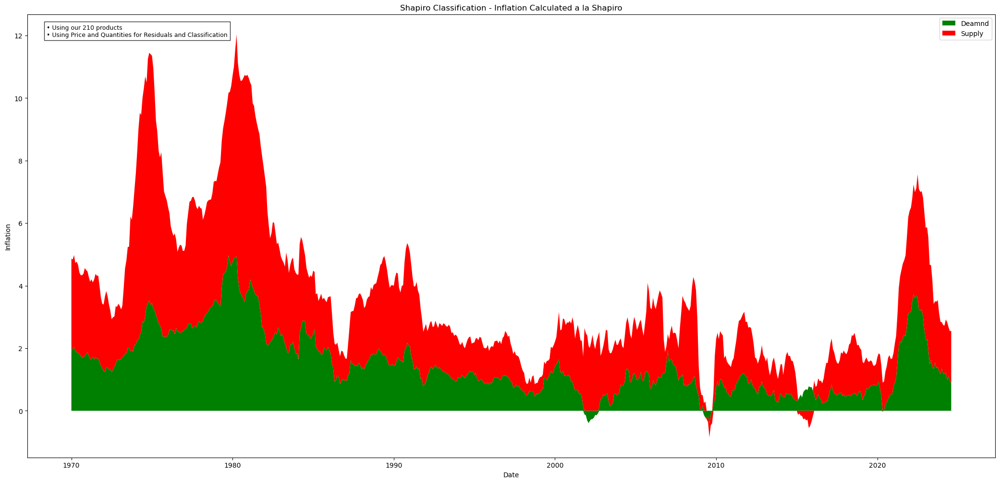

In [93]:
plot_graphs(inflation_shapiro_final, "Shapiro Classification - Inflation Calculated a la Shapiro", "• Using our 210 products \n• Using Price and Quantities for Residuals and Classification")

<module 'matplotlib.pyplot' from '/opt/anaconda3/envs/BofC_shocks_production/lib/python3.13/site-packages/matplotlib/pyplot.py'>

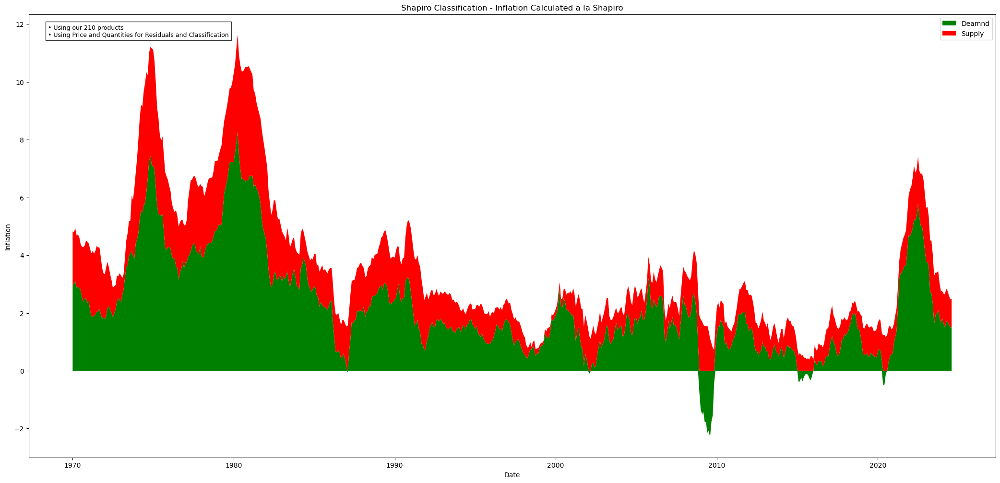

In [94]:
plot_graphs(inflation_IO_final, "Shapiro Classification - Inflation Calculated a la Shapiro", "• Using our 210 products \n• Using Price and Quantities for Residuals and Classification")